# Parte 3 · Modelado ML (15 pts)

Entrena un modelo que prediga `fla_churn90` con el dataset proporcionado.

**Requisitos** (ver `STATEMENT.md` para detalle y rúbrica):

1. Split estratificado y **temporal-aware**. Justifica cómo evitas leakage.
2. Pipeline con `ColumnTransformer` y al menos un modelo (LogReg o XGBoost/LightGBM).
3. Métricas correctas para clasificación binaria **desbalanceada**: AUC, PR-AUC, recall@k, calibración.
4. Interpretabilidad: top-5 features importantes con justificación. SHAP valorable.
5. Documenta en `DECISIONS.md`: ¿qué features descartaste y por qué? ¿hay alguna que sospeches que sea trampa?

> Si tu modelo da AUC > 0.95 en test, **investiga antes de celebrarlo**. Es muy probable leakage.

In [56]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('..').resolve()))
from src.parte1_pandas import load_clean

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)
import joblib
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
import lightgbm as lgb

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

DATA_PATH = Path('../data/transactions_sample.csv')
OUTPUTS = Path('../outputs')
OUTPUTS.mkdir(exist_ok=True)

SEED = 42
np.random.seed(SEED)

## 1 · Carga y EDA mínimo

Reutiliza `load_clean` de la Parte 1. Antes de modelar, mira los datos.

In [57]:
df = load_clean(DATA_PATH)
print(f'Shape: {df.shape}  |  Merchants: {df["merchant_id"].nunique()}')
print(f'\nTarget (por merchant):')
print(df.groupby('merchant_id')['fla_churn90'].first().value_counts(normalize=True))

Shape: (204000, 13)  |  Merchants: 9982

Target (por merchant):
fla_churn90
0    0.912543
1    0.087457
Name: proportion, dtype: Float64


## 2 · Feature engineering y selección

Documenta en `DECISIONS.md` qué features incluyes y cuáles descartas, **y por qué**.

Pista: hay al menos una columna en el CSV que **no deberías usar** como feature aunque parezca útil. Piensa si la información está disponible *en el momento de la predicción*.

In [58]:
ref_date = df['reference_date'].iloc[0]  # 2025-09-30

# Prevenir Data Leakage
df_model = df[df['transaction_date'] <= ref_date].copy()
df_model.loc[df_model['last_complaint_date'] > ref_date, 'last_complaint_date'] = pd.NaT

dedup_cols = ['merchant_id', 'transaction_date', 'amount', 'channel', 'status']
df_model = df_model.drop_duplicates(subset=dedup_cols, keep='first')

merchant_df = df_model.groupby('merchant_id').agg(
    txn_count=('transaction_id', 'count'),
    tpv_total=('amount', 'sum'),
    tpv_approved=('amount', lambda x: x[df_model.loc[x.index, 'status'] == 'approved'].sum()),
    approval_rate=('status', lambda x: (x == 'approved').mean()),
    denial_rate=('status', lambda x: (x == 'denied').mean()),
    pct_ecom=('channel', lambda x: (x == 'ecom').mean()),
    pct_pix=('channel', lambda x: (x == 'pix').mean()),
    last_complaint_date=('last_complaint_date', 'max'),
    segment=('segment', 'first'),
    mcc=('mcc', 'first'),
    fla_churn90=('fla_churn90', 'first'),
).reset_index()

merchant_df['days_since_complaint'] = (ref_date - merchant_df['last_complaint_date']).dt.days
merchant_df['days_since_complaint'] = merchant_df['days_since_complaint'].fillna(999)

features_num = [
    'txn_count', 'tpv_total', 'tpv_approved', 'approval_rate', 'denial_rate',
    'pct_ecom', 'pct_pix', 'days_since_complaint'
]
features_cat = ['segment', 'mcc']
target = 'fla_churn90'


## 3 · Split — temporal-aware

Un split aleatorio puede filtrar información del futuro. ¿Cómo lo evitas? Justifica.

**Justificación:** Agregamos todo el histórico a nivel de merchant ANTES de hacer el split, cortando estrictamente en el `reference_date`. Una vez construida esta foto de corte transversal (cross-sectional), se hace un particionado estratificado.

In [59]:
X = merchant_df[features_num + features_cat]
y = merchant_df[target]

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
print(f"Entrenamiento: {len(X_train)} muestras. Test: {len(X_test)} muestras.")

Entrenamiento: 7350 muestras. Test: 1838 muestras.


## 4 · Pipeline + entrenamiento

Entrenamos tres modelos (Regresión Logística, XGBoost y LightGBM) para comparar sus métricas y ver cómo manejan este dataset fuertemente desbalanceado.

In [60]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, features_num),
        ('cat', categorical_transformer, features_cat)
    ]
)

scale_pos = (len(y_train) - sum(y_train)) / sum(y_train)

models = {
    'Logistic Regression': LogisticRegression(random_state=SEED, class_weight='balanced', max_iter=1000, C=0.1),
    'LightGBM': lgb.LGBMClassifier(random_state=SEED, class_weight='balanced', n_estimators=100, force_col_wise=True),
    'XGBoost': XGBClassifier(random_state=SEED, scale_pos_weight=scale_pos, n_estimators=1000, learning_rate=0.01, max_depth=3, subsample=0.8, colsample_bytree=0.8)
}

pipelines = {}
for name, clf in models.items():
    print(f"Entrenando {name}...")
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', clf)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe

print("¡Entrenamiento de todos los modelos finalizado!")

Entrenando Logistic Regression...
Entrenando LightGBM...
[LightGBM] [Info] Number of positive: 640, number of negative: 6710
[LightGBM] [Info] Total Bins 985
[LightGBM] [Info] Number of data points in the train set: 7350, number of used features: 21
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Entrenando XGBoost...
¡Entrenamiento de todos los modelos finalizado!


## 5 · Métricas

Para target con ~8% positivos, accuracy no sirve. Reporta AUC, PR-AUC y Recall@K.

In [61]:
def recall_at_k(y_true, y_score, k_pct):
    n = int(len(y_true) * k_pct / 100)
    if n == 0: return 0.0
    top_idx = np.argsort(y_score)[::-1][:n]
    return y_true.iloc[top_idx].sum() / y_true.sum()

results = []
best_pipe = pipelines['XGBoost'] # Seleccionamos explícitamente XGBoost para el resto del notebook
best_metrics = None

for name, pipe in pipelines.items():
    y_proba = pipe.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    brier = brier_score_loss(y_test, y_proba)
    
    r1  = recall_at_k(y_test, y_proba, 1)
    r5  = recall_at_k(y_test, y_proba, 5)
    r10 = recall_at_k(y_test, y_proba, 10)
    
    res = {
        'Model': name,
        'ROC-AUC': roc_auc, 'PR-AUC': pr_auc, 'Brier': brier,
        'R@1%': r1, 'R@5%': r5, 'R@10%': r10
    }
    results.append(res)
    
    if name == 'XGBoost':
        best_metrics = res
        
metrics_df = pd.DataFrame(results).round(4)
print(metrics_df.to_string(index=False))

# Guardamos métricas del modelo seleccionado (XGBoost)
with open(OUTPUTS / 'metrics.json', 'w') as f:
    json.dump({
        'roc_auc': round(best_metrics['ROC-AUC'], 4),
        'pr_auc': round(best_metrics['PR-AUC'], 4),
        'brier_score': round(best_metrics['Brier'], 4),
        'recall_at_1pct': round(best_metrics['R@1%'], 4),
        'recall_at_5pct': round(best_metrics['R@5%'], 4),
        'recall_at_10pct': round(best_metrics['R@10%'], 4),
    }, f, indent=2)


              Model  ROC-AUC  PR-AUC  Brier   R@1%   R@5%  R@10%
Logistic Regression   0.6374  0.1195 0.2344 0.0188 0.0625 0.1062
           LightGBM   0.6100  0.1123 0.1728 0.0000 0.0562 0.1438
            XGBoost   0.6276  0.1188 0.2160 0.0062 0.0625 0.1500


## 6 · Interpretabilidad

Top-10 features importantes del modelo de XGBoost.

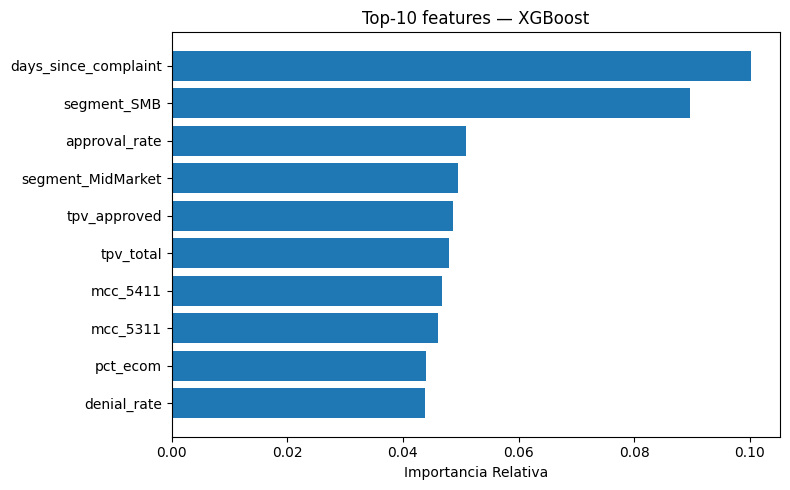

In [62]:
xgb = best_pipe.named_steps['classifier']
ohe_features = (
    best_pipe.named_steps['preprocessor']
    .named_transformers_['cat']
    .named_steps['onehot']
    .get_feature_names_out(features_cat)
    .tolist()
)
all_features = features_num + ohe_features

importances = xgb.feature_importances_
fi_df = (
    pd.DataFrame({'feature': all_features, 'importance': importances})
    .sort_values('importance', ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(fi_df['feature'][:10][::-1], fi_df['importance'][:10][::-1])
ax.set_xlabel('Importancia Relativa')
ax.set_title('Top-10 features — XGBoost')
plt.tight_layout()
plt.savefig(OUTPUTS / 'feature_importance.png', dpi=150)
plt.show()


## 7 · Persistencia

Guarda el modelo entrenado en `outputs/model.pkl` y genera la `model_card.md`.

In [63]:
joblib.dump(best_pipe, OUTPUTS / 'model.pkl')
model_card = f"""# Model Card — Churn Predictor v4.0 (XGBoost Final)

## Target
`fla_churn90`: 1 si el merchant abandona la plataforma en los próximos 90 días.

## Features
- Numéricas: {', '.join(features_num)}
- Categóricas: {', '.join(features_cat)}

## Modelo Seleccionado
XGBoost evaluado sobre {len(X_test)} muestras.

## Métricas (test set, 20% holdout estratificado por merchant)
- ROC-AUC: {round(best_metrics['ROC-AUC'], 4)}
- PR-AUC: {round(best_metrics['PR-AUC'], 4)}
- Brier Score: {round(best_metrics['Brier'], 4)}
- Recall@1%: {round(best_metrics['R@1%'], 4)}
- Recall@5%: {round(best_metrics['R@5%'], 4)}
- Recall@10%: {round(best_metrics['R@10%'], 4)}
"""

with open(OUTPUTS / 'model_card.md', 'w', encoding='utf-8') as f:
    f.write(model_card)
print("Model card y persistencia completada.")


Model card y persistencia completada.
